In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn 
import joblib

In [10]:
from pathlib import Path
data_path = Path(r"D:\ML-Projects\SpamMessageClassifier\spam.csv")

print("File exists:", data_path.is_file())

df = pd.read_csv(data_path, encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)



File exists: True
Dataset loaded successfully!
Dataset shape: (5572, 5)


In [9]:
df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [14]:
print("Columns name")
print(df.columns.tolist())

Columns name
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [13]:
print("data type")
print(df.dtypes)

data type
v1            str
v2            str
Unnamed: 2    str
Unnamed: 3    str
Unnamed: 4    str
dtype: object


In [15]:
print("Missing values")
print(df.isnull())

Missing values
         v1     v2  Unnamed: 2  Unnamed: 3  Unnamed: 4
0     False  False        True        True        True
1     False  False        True        True        True
2     False  False        True        True        True
3     False  False        True        True        True
4     False  False        True        True        True
...     ...    ...         ...         ...         ...
5567  False  False        True        True        True
5568  False  False        True        True        True
5569  False  False        True        True        True
5570  False  False        True        True        True
5571  False  False        True        True        True

[5572 rows x 5 columns]


In [16]:
df = df[["v1", "v2"]].copy()

print(df.isnull().sum())

v1    0
v2    0
dtype: int64


In [23]:
df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [25]:
print("Total missing values:",df.isnull().sum())

Total missing values: label      0
message    0
dtype: int64


In [28]:
print(df["label"].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [29]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 403


In [30]:
df = df.drop_duplicates().copy()
print("after removing duplicates:", df.shape)

after removing duplicates: (5169, 2)


In [31]:
print(df["label"].value_counts())

label
ham     4516
spam     653
Name: count, dtype: int64


In [33]:
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.lower()

df = df[df["label"].isin(["ham","spam"])].copy()


In [35]:
X = df["message"]
y = df["label"]

print("Feature:", X.shape)
print("Target:", y.shape)

Feature: (5169,)
Target: (5169,)


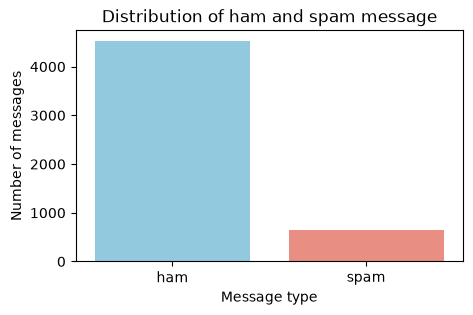

In [52]:
plt.figure(figsize=(5,3))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette={"ham": "skyblue", "spam": "salmon"},
    legend=False
)

plt.title("Distribution of ham and spam message")
plt.xlabel("Message type")
plt.ylabel("Number of messages")

plt.show()

In [56]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=40,stratify=y)

print("Training Messages:",len(X_train))
print("Testing Messages:", len(X_test))

print("Training label counts:",y_train.value_counts())

Training Messages: 4135
Testing Messages: 1034
Training label counts: label
ham     3613
spam     522
Name: count, dtype: int64


In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (4135, 30883)
Testing matrix: (1034, 30883)


In [58]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [59]:
# Predict labels for test messages
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print(y_pred[:10])

Predictions completed!
['ham' 'spam' 'ham' 'spam' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [60]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.26 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.77       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.96      0.95      0.95      1034



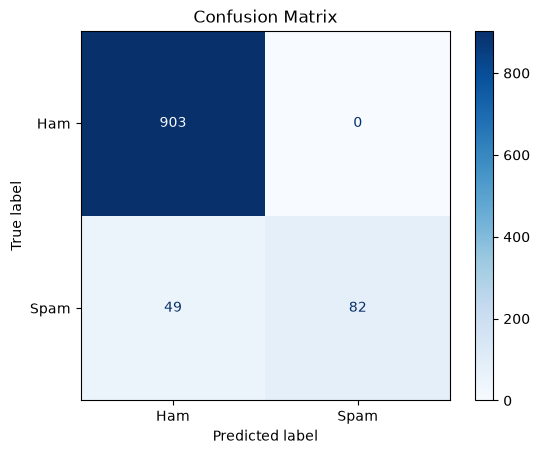

[[903   0]
 [ 49  82]]


In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

print(cm)

In [62]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

for alpha in [0.1, 0.3, 0.5, 0.7, 1.0]:
    temp_model = MultinomialNB(alpha=alpha)
    temp_model.fit(X_train_tfidf, y_train)

    temp_pred = temp_model.predict(X_test_tfidf)

    spam_precision = precision_score(
        y_test, temp_pred, pos_label="spam"
    )
    spam_recall = recall_score(
        y_test, temp_pred, pos_label="spam"
    )
    spam_f1 = f1_score(
        y_test, temp_pred, pos_label="spam"
    )
    accuracy = accuracy_score(y_test, temp_pred)

    print(f"\nAlpha: {alpha}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Spam Precision: {spam_precision * 100:.2f}%")
    print(f"Spam Recall: {spam_recall * 100:.2f}%")
    print(f"Spam F1-score: {spam_f1 * 100:.2f}%")



Alpha: 0.1
Accuracy: 98.84%
Spam Precision: 98.37%
Spam Recall: 92.37%
Spam F1-score: 95.28%

Alpha: 0.3
Accuracy: 98.26%
Spam Precision: 100.00%
Spam Recall: 86.26%
Spam F1-score: 92.62%

Alpha: 0.5
Accuracy: 97.39%
Spam Precision: 100.00%
Spam Recall: 79.39%
Spam F1-score: 88.51%

Alpha: 0.7
Accuracy: 96.42%
Spam Precision: 100.00%
Spam Recall: 71.76%
Spam F1-score: 83.56%

Alpha: 1.0
Accuracy: 95.26%
Spam Precision: 100.00%
Spam Recall: 62.60%
Spam F1-score: 77.00%


In [63]:
model = MultinomialNB(alpha=0.1)
model.fit(X_train_tfidf, y_train)

print("Best model trained successfully!")

Best model trained successfully!


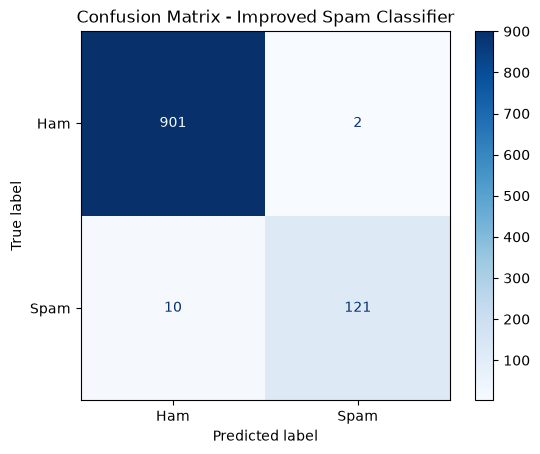

[[901   2]
 [ 10 121]]


In [65]:
# Predict using the improved model
y_pred = model.predict(X_test_tfidf)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

# Display the matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Improved Spam Classifier")
plt.show()

print(cm)


In [66]:
from sklearn.metrics import classification_report, accuracy_score

print("Final Model Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nFinal Classification Report:")
print(classification_report(y_test, y_pred))

Final Model Accuracy: 98.84 %

Final Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.92      0.95       131

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



In [67]:

# Example messages
sample_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting today?",
    "URGENT! You have won a cash reward. Call now!",
    "Please send me the class notes."
]

# Convert messages using the already trained TF-IDF vectorizer
sample_tfidf = vectorizer.transform(sample_messages)

# Predict using the improved model
sample_predictions = model.predict(sample_tfidf)

# Display results
for message, prediction in zip(sample_messages, sample_predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 50)


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
--------------------------------------------------
Message: Hey, are we meeting today?
Prediction: HAM
--------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
--------------------------------------------------
Message: Please send me the class notes.
Prediction: HAM
--------------------------------------------------


## Conclusion

The Spam Message Classifier was developed using the Multinomial Naive Bayes algorithm and TF-IDF vectorization. The model was evaluated on a test dataset of 1,034 messages and achieved an accuracy of 98.84%.

The spam class achieved 98% precision, 92% recall, and a 95% F1-score. The model was also tested on sample messages and correctly classified the given examples as spam or ham.

This project demonstrates how machine learning and text preprocessing can be used to classify SMS messages. Further improvements can focus on identifying the remaining spam messages that are missed by the model.